# Exercise 4

####Import packages

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.optim.lr_scheduler import StepLR

## Task 1
(3 points)

Implement the training loop for one training epoch.
An epoch trains on the whole training dataset once.

In [2]:
def train(model, use_cuda, train_loader, optimizer, epoch, log_interval):
    """
    Train one epoch
    
    model -- the neural network
    use_cuda -- true if GPU should be used
    train_loader -- data loader
    optimizer -- network optimizer
    epoch -- number of current epoch
    log_interval -- number of training steps between logs
    """
    # TODO: set the model to train mode
    model.train()

    # TODO: enumerate over the dataloader to get mini batches
    #       of images and ground truth labels
    # HINT: the builtin python function enumerate() also gives you indices
    for batch_idx, (data, target) in enumerate(train_loader):
        if use_cuda:
            # transfer to GPU
            data = data.cuda()
            target = target.cuda()

        # TODO: set the optimizers gradients to zero
        optimizer.zero_grad()

        # TODO: run the network
        output = model(data)

        # TODO: compute negative log likelihood loss
        loss = F.nll_loss(output, target)

        # TODO: do backpropagation
        loss.backward()

        # TODO: optimize
        optimizer.step()

        # TODO: print current loss for every nth ("log_interval"th) iteration
        if batch_idx % log_interval == 0:
            print('Train Epoch: {} [{}/{} ({:.0f}%)]\tLoss: {:.6f}'.format(
                epoch,
                batch_idx * len(data),
                len(train_loader.dataset),
                100. * batch_idx / len(train_loader),
                loss.item()))


We already implemented the validation function for you (this is essentially validate() from the last exercise)

In [23]:
def validate(model, use_cuda, test_loader):
    """
    Compute test metrics
    
    model -- the neural network
    use_cuda -- true if GPU should be used
    test_loader -- data loader
    """
    # create a 10x10 grid of subplots
    _, axis = plt.subplots(10, 10)

    # set model to evaluation mode
    model.eval()
    test_loss = 0
    correct = 0
    plotted = 0

    # disable gradients globally
    with torch.no_grad():
        for batch_idx, (data, target) in enumerate(test_loader):
            # for each batch
            if use_cuda:
                # transfer to GPU
                data = data.cuda()
                target = target.cuda()

            # run network and compute metrics
            output = model(data)
            test_loss += F.nll_loss(output, target, reduction='sum').item()

            img_correct = pred.eq(target.view_as(pred))
            correct += pred.eq(target.view_as(pred)).sum().item()

            # plot the first 100 images
            img_idx = 0
            data = data.cpu().numpy()

            while plotted < 100 and img_idx < data.shape[0]:
                # compute position of ith image in the grid
                y = plotted % 10
                x = plotted // 10

                # convert image tensor to numpy array and normalize to [0, 1]
                img = data[img_idx, 0]
                img = (img - np.min(img)) / (np.max(img) - np.min(img))

                # make wrongly predicted images red
                img = np.stack([img] * 3, 2)
                if img_correct[img_idx] == 0:
                    img[:, :, 1:] = 0.0

                # disable axis and show image
                axis[y][x].axis('off')
                axis[y][x].imshow(img)

                # show the predicted class next to each image
                axis[y][x].text(30, 25, pred[img_idx].item())

                plotted += 1
                img_idx += 1

    test_loss /= len(test_loader.dataset)

    # show results
    print('\nTest set: Average loss: {:.4f}, Accuracy: {}/{} ({:.2f}%)\n'.format(
        test_loss, correct, len(test_loader.dataset),
        100. * correct / len(test_loader.dataset)))
    plt.show()

## Task 2
(4 points)

Implement a five-layer fully connected neural network.
The dimensions (without batch size) should change like this: 784->200->100->60->30->10
Use log softmax to compute the class predictions.

Run the code at the end of the notebook to train and validate your implementation.

### Task 2.1
* sigmoid non-linear activation function
* note that the last layer does not need an activation function!

### Task 2.2
* add a new class "FCNet2"
* replace sigmoid with ReLU

### Task 2.3
* add a new class "FCNet2"
* add batch normalization to the first and third layers (note the difference between 1D/2D/3D versions)


**NOTE:** The perfomance should improve slightly with each step. However, due to the random weight initialization applied by PyTorch, your results may vary a bit between trainings.

In [16]:
class FCNet1(nn.Module):
    """
    Fully Connected Neural Network
    
    Five fully connected layers with sigmoid non-linearity
    
    Dimensions
    784->200->100->60->30->10
    """

    def __init__(self):
        super(FCNet1, self).__init__()

        # TODO: initialize network layers
        # HINT: take a look at "torch.nn" (imported as "nn")
        self.fc1 = nn.Linear(784, 200)
        self.fc2 = nn.Linear(200, 100)
        self.fc3 = nn.Linear(100, 60)
        self.fc4 = nn.Linear(60, 30)
        self.fc5 = nn.Linear(30, 10)

    def forward(self, x):
        # TODO: reshape batch of images to batch of 1D vectors
        #x = x.view(x.size(0), -1)
        x = torch.flatten(x, 1)

        # TODO: run network layers
        x = torch.sigmoid(self.fc1(x))
        x = torch.sigmoid(self.fc2(x))
        x = torch.sigmoid(self.fc3(x))
        x = torch.sigmoid(self.fc4(x))
        x = self.fc5(x)

        # TODO: compute log softmax over the output
        # HINT: take a look at "torch.nn.functional" (imported as "F")
        output = F.log_softmax(x, dim=1)

        return output

In [17]:
class FCNet2(nn.Module):
    def __init__(self):
        super(FCNet2, self).__init__()
        self.fc1 = nn.Linear(784, 200)
        self.fc2 = nn.Linear(200, 100)
        self.fc3 = nn.Linear(100, 60)
        self.fc4 = nn.Linear(60, 30)
        self.fc5 = nn.Linear(30, 10)

    def forward(self, x):
        x = x.view(x.size(0), -1)

        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = F.relu(self.fc3(x))
        x = F.relu(self.fc4(x))
        x = self.fc5(x)

        return F.log_softmax(x, dim=1)

        pass

In [18]:
class FCNet3(nn.Module):
    def __init__(self):
        super(FCNet3, self).__init__()
        self.fc1 = nn.Linear(784, 200)
        self.bn1 = nn.BatchNorm1d(200)
        self.fc2 = nn.Linear(200, 100)
        self.fc3 = nn.Linear(100, 60)
        self.bn3 = nn.BatchNorm1d(60)
        self.fc4 = nn.Linear(60, 30)
        self.fc5 = nn.Linear(30, 10)

    def forward(self, x):
        x = x.view(x.size(0), -1)

        x = F.relu(self.bn1(self.fc1(x)))
        x = F.relu(self.fc2(x))
        x = F.relu(self.bn3(self.fc3(x)))
        x = F.relu(self.fc4(x))
        x = self.fc5(x)

        return F.log_softmax(x, dim=1)
        pass

## Task 3
(3 points)

Implement a convolutional neural network, consisting of two convolutional and two fully connected layers.
This time, the dimensions (without batch size) should change like this: 1x28x28->32x26x26->64x12x12->128->10

### Task 3.1
* two convolutional layers (kernel size 3)
* two fully-connected layers
* ReLU activation function

### Task 3.2
* add batch normalization to first convolutional and first fully connected layer

### Task 3.3
* use max pooling instead of stride to reduce the dimensions to 64x12x12

In [19]:
class ConvNet1(nn.Module):
    """
    Convolutional Neural Network
    
    Two convolutional layers and two fully connected layers
    
    Dimensions:
    1x28x28->32x26x26->64x12x12->128->10
    """

    def __init__(self):
        super(ConvNet1, self).__init__()

        # TODO: initialize network layers
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=2)

        self.fc1 = nn.Linear(64 * 12 * 12, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        # TODO: run convolutional layers
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))

        # TODO: reshape batch of images to batch of 1D vectors
        x = x.view(x.size(0), -1)

        # TODO: run fully connected layers
        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        # TODO: compute log softmax over the output
        output = F.log_softmax(x, dim=1)

        return output

In [20]:
class ConvNet2(nn.Module):
    def __init__(self):
        super(ConvNet2, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=2)

        self.fc1 = nn.Linear(64 * 12 * 12, 128)
        self.bn2 = nn.BatchNorm1d(128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.conv2(x))

        x = x.view(x.size(0), -1)

        x = F.relu(self.bn2(self.fc1(x)))
        x = self.fc2(x)

        return F.log_softmax(x, dim=1)
        pass

In [21]:
"""
Task 3.3
use max pooling instead of stride to reduce the dimensions to 64x12x12
"""


class ConvNet3(nn.Module):
    def __init__(self):
        super(ConvNet3, self).__init__()

        self.conv1 = nn.Conv2d(1, 32, 3)
        self.conv2 = nn.Conv2d(32, 64, 3, stride=1)
        self.fc1 = nn.Linear(64 * 12 * 12, 128)
        self.fc2 = nn.Linear(128, 10)
        self.bn1 = nn.BatchNorm2d(32)
        self.bn2 = nn.BatchNorm1d(128)
        self.pool1 = nn.MaxPool2d(2, 2)

        """
         ['kernel_size', 'stride', 'padding', 'dilation',
             'return_indices', 'ceil_mode']
        original: 64 * 24 * 24
        target:  64 * 12 * 12
        Input feature map         Output
        1 3 | 2 4                  5 4
        5 2 | 1 0                  8 9
        ----+-----
        6 8 | 3 1
        2 4 | 7 9


        """




    """ what
    A max pooling layer moves a small window across a feature map
    and returns the largest value inside each window.

    Input feature map         Output
    1 3 | 2 4                  5 4
    5 2 | 1 0                  8 9
    ----+-----
    6 8 | 3 1
    2 4 | 7 9


    """

    """ why
    1. it can be used to reduce the dimensions
    2. Max pooling is useful when we want a more compact spatial
    representation and can afford to lose some local detail.
    like Image classification
    """

    """how can we use it
    1. define
    2. Hierarchical relationships
    3. shape of tensor
    """


def forward(self, x):
    output = F.relu(self.bn1(self.conv1(x)))
    # 1 * 28 * 28 -> 32 * 26 * 26
    # floor((length − window) / stride) + 1 (28-3)/1+1

    output = self.pool1(F.relu(self.conv2(output)))
    """
    Hierarchical relationships =
        1.convolution layer is first layer
        2.activation layer is second layer
        3.max pooling layer is third layer
    """
    output = torch.flatten(output, start_dim=1)

    output = F.relu(self.bn2(self.fc1(output)))

    output = F.log_softmax(self.fc2(output), 1)

    return output

Train Epoch: 1 [0/60000 (0%)]	Loss: 2.307786
Train Epoch: 1 [6400/60000 (11%)]	Loss: 0.693358
Train Epoch: 1 [12800/60000 (21%)]	Loss: 0.511620
Train Epoch: 1 [19200/60000 (32%)]	Loss: 0.243659
Train Epoch: 1 [25600/60000 (43%)]	Loss: 0.153606
Train Epoch: 1 [32000/60000 (53%)]	Loss: 0.145557
Train Epoch: 1 [38400/60000 (64%)]	Loss: 0.158628
Train Epoch: 1 [44800/60000 (75%)]	Loss: 0.186881
Train Epoch: 1 [51200/60000 (85%)]	Loss: 0.048467
Train Epoch: 1 [57600/60000 (96%)]	Loss: 0.220320

Test set: Average loss: 0.1292, Accuracy: 9625/10000 (96.25%)



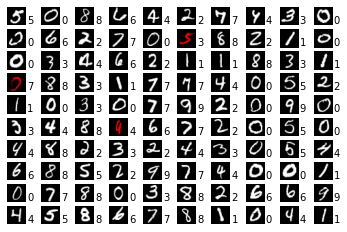

Train Epoch: 2 [0/60000 (0%)]	Loss: 0.077652
Train Epoch: 2 [6400/60000 (11%)]	Loss: 0.062726
Train Epoch: 2 [12800/60000 (21%)]	Loss: 0.021053
Train Epoch: 2 [19200/60000 (32%)]	Loss: 0.082066
Train Epoch: 2 [25600/60000 (43%)]	Loss: 0.088934
Train Epoch: 2 [32000/60000 (53%)]	Loss: 0.060896
Train Epoch: 2 [38400/60000 (64%)]	Loss: 0.189433
Train Epoch: 2 [44800/60000 (75%)]	Loss: 0.021753
Train Epoch: 2 [51200/60000 (85%)]	Loss: 0.036680
Train Epoch: 2 [57600/60000 (96%)]	Loss: 0.088128

Test set: Average loss: 0.0995, Accuracy: 9708/10000 (97.08%)



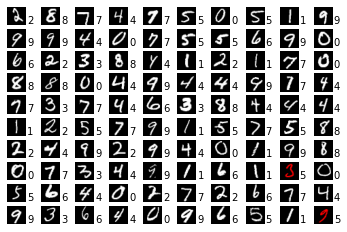

Train Epoch: 3 [0/60000 (0%)]	Loss: 0.126878
Train Epoch: 3 [6400/60000 (11%)]	Loss: 0.088515
Train Epoch: 3 [12800/60000 (21%)]	Loss: 0.010964
Train Epoch: 3 [19200/60000 (32%)]	Loss: 0.142434
Train Epoch: 3 [25600/60000 (43%)]	Loss: 0.005247
Train Epoch: 3 [32000/60000 (53%)]	Loss: 0.046767
Train Epoch: 3 [38400/60000 (64%)]	Loss: 0.081331
Train Epoch: 3 [44800/60000 (75%)]	Loss: 0.051112
Train Epoch: 3 [51200/60000 (85%)]	Loss: 0.049363
Train Epoch: 3 [57600/60000 (96%)]	Loss: 0.064800

Test set: Average loss: 0.0829, Accuracy: 9790/10000 (97.90%)



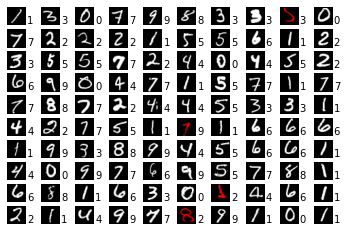

Train Epoch: 4 [0/60000 (0%)]	Loss: 0.054373
Train Epoch: 4 [6400/60000 (11%)]	Loss: 0.043865
Train Epoch: 4 [12800/60000 (21%)]	Loss: 0.003619
Train Epoch: 4 [19200/60000 (32%)]	Loss: 0.035981
Train Epoch: 4 [25600/60000 (43%)]	Loss: 0.017214
Train Epoch: 4 [32000/60000 (53%)]	Loss: 0.016948
Train Epoch: 4 [38400/60000 (64%)]	Loss: 0.039720
Train Epoch: 4 [44800/60000 (75%)]	Loss: 0.057102
Train Epoch: 4 [51200/60000 (85%)]	Loss: 0.007797
Train Epoch: 4 [57600/60000 (96%)]	Loss: 0.002041

Test set: Average loss: 0.0757, Accuracy: 9809/10000 (98.09%)



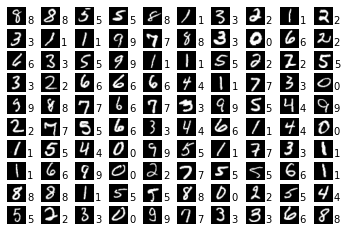

Train Epoch: 5 [0/60000 (0%)]	Loss: 0.040400
Train Epoch: 5 [6400/60000 (11%)]	Loss: 0.001766
Train Epoch: 5 [12800/60000 (21%)]	Loss: 0.000685
Train Epoch: 5 [19200/60000 (32%)]	Loss: 0.034390
Train Epoch: 5 [25600/60000 (43%)]	Loss: 0.017466
Train Epoch: 5 [32000/60000 (53%)]	Loss: 0.000676
Train Epoch: 5 [38400/60000 (64%)]	Loss: 0.024974
Train Epoch: 5 [44800/60000 (75%)]	Loss: 0.013620
Train Epoch: 5 [51200/60000 (85%)]	Loss: 0.138223
Train Epoch: 5 [57600/60000 (96%)]	Loss: 0.007181

Test set: Average loss: 0.0794, Accuracy: 9813/10000 (98.13%)



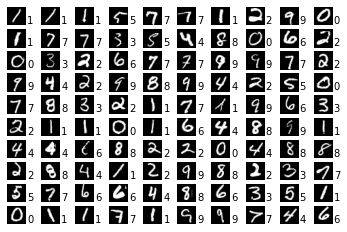

Train Epoch: 6 [0/60000 (0%)]	Loss: 0.001611
Train Epoch: 6 [6400/60000 (11%)]	Loss: 0.003970
Train Epoch: 6 [12800/60000 (21%)]	Loss: 0.000706
Train Epoch: 6 [19200/60000 (32%)]	Loss: 0.000177
Train Epoch: 6 [25600/60000 (43%)]	Loss: 0.001066
Train Epoch: 6 [32000/60000 (53%)]	Loss: 0.000141
Train Epoch: 6 [38400/60000 (64%)]	Loss: 0.000485
Train Epoch: 6 [44800/60000 (75%)]	Loss: 0.002410
Train Epoch: 6 [51200/60000 (85%)]	Loss: 0.115764
Train Epoch: 6 [57600/60000 (96%)]	Loss: 0.002595

Test set: Average loss: 0.0814, Accuracy: 9821/10000 (98.21%)



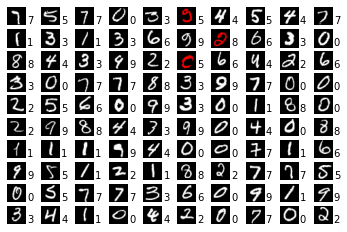

Train Epoch: 7 [0/60000 (0%)]	Loss: 0.026773
Train Epoch: 7 [6400/60000 (11%)]	Loss: 0.106298
Train Epoch: 7 [12800/60000 (21%)]	Loss: 0.000217
Train Epoch: 7 [19200/60000 (32%)]	Loss: 0.101231
Train Epoch: 7 [25600/60000 (43%)]	Loss: 0.003514
Train Epoch: 7 [32000/60000 (53%)]	Loss: 0.002067
Train Epoch: 7 [38400/60000 (64%)]	Loss: 0.001754
Train Epoch: 7 [44800/60000 (75%)]	Loss: 0.000839
Train Epoch: 7 [51200/60000 (85%)]	Loss: 0.000741
Train Epoch: 7 [57600/60000 (96%)]	Loss: 0.004248

Test set: Average loss: 0.0855, Accuracy: 9817/10000 (98.17%)



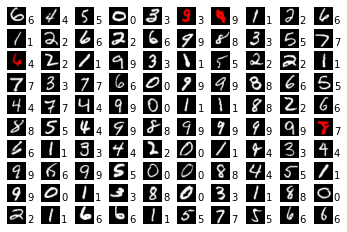

Train Epoch: 8 [0/60000 (0%)]	Loss: 0.000156
Train Epoch: 8 [6400/60000 (11%)]	Loss: 0.002258
Train Epoch: 8 [12800/60000 (21%)]	Loss: 0.003590
Train Epoch: 8 [19200/60000 (32%)]	Loss: 0.025586
Train Epoch: 8 [25600/60000 (43%)]	Loss: 0.000162
Train Epoch: 8 [32000/60000 (53%)]	Loss: 0.001864
Train Epoch: 8 [38400/60000 (64%)]	Loss: 0.001034
Train Epoch: 8 [44800/60000 (75%)]	Loss: 0.000822
Train Epoch: 8 [51200/60000 (85%)]	Loss: 0.000461
Train Epoch: 8 [57600/60000 (96%)]	Loss: 0.000542

Test set: Average loss: 0.0867, Accuracy: 9825/10000 (98.25%)



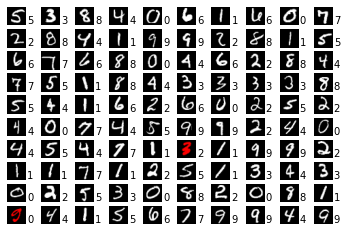

Train Epoch: 9 [0/60000 (0%)]	Loss: 0.002177
Train Epoch: 9 [6400/60000 (11%)]	Loss: 0.000268
Train Epoch: 9 [12800/60000 (21%)]	Loss: 0.000663
Train Epoch: 9 [19200/60000 (32%)]	Loss: 0.002101
Train Epoch: 9 [25600/60000 (43%)]	Loss: 0.044512
Train Epoch: 9 [32000/60000 (53%)]	Loss: 0.000218
Train Epoch: 9 [38400/60000 (64%)]	Loss: 0.000330
Train Epoch: 9 [44800/60000 (75%)]	Loss: 0.009551
Train Epoch: 9 [51200/60000 (85%)]	Loss: 0.000752
Train Epoch: 9 [57600/60000 (96%)]	Loss: 0.000245

Test set: Average loss: 0.0881, Accuracy: 9814/10000 (98.14%)



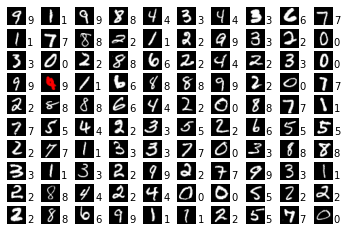

Train Epoch: 10 [0/60000 (0%)]	Loss: 0.000135
Train Epoch: 10 [6400/60000 (11%)]	Loss: 0.000109
Train Epoch: 10 [12800/60000 (21%)]	Loss: 0.003004
Train Epoch: 10 [19200/60000 (32%)]	Loss: 0.000357
Train Epoch: 10 [25600/60000 (43%)]	Loss: 0.000395
Train Epoch: 10 [32000/60000 (53%)]	Loss: 0.088238
Train Epoch: 10 [38400/60000 (64%)]	Loss: 0.000637
Train Epoch: 10 [44800/60000 (75%)]	Loss: 0.014663
Train Epoch: 10 [51200/60000 (85%)]	Loss: 0.000781
Train Epoch: 10 [57600/60000 (96%)]	Loss: 0.000686

Test set: Average loss: 0.0893, Accuracy: 9820/10000 (98.20%)



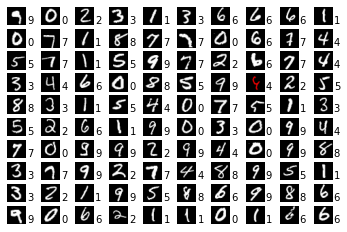

In [22]:
batch_size = 64
test_batch_size = 1000
epochs = 10
lr = 1.0
gamma = 0.7
log_interval = 100

# use GPU if available
use_cuda = torch.cuda.is_available()
kwargs = {'num_workers': 1, 'pin_memory': True} if use_cuda else {}

# initialize data loaders
train_loader = torch.utils.data.DataLoader(
    datasets.MNIST('../data', train=True, download=True,
                   transform=transforms.Compose([
                       transforms.ToTensor(),
                       transforms.Normalize((0.1307,), (0.3081,))
                   ])), batch_size=batch_size, shuffle=True, **kwargs)

test_loader = torch.utils.data.DataLoader(
    datasets.MNIST('../data', train=False,
                   transform=transforms.Compose([
                       transforms.ToTensor(),
                       transforms.Normalize((0.1307,), (0.3081,))
                   ])),
    batch_size=test_batch_size, shuffle=True, **kwargs)

model = FCNet2()
if use_cuda:
    model = model.cuda()

# initialize optimizer and scheduler
optimizer = optim.Adadelta(model.parameters(), lr=lr)
scheduler = StepLR(optimizer, step_size=1, gamma=gamma)

for epoch in range(1, epochs + 1):
    # train one epoch
    train(model, use_cuda, train_loader, optimizer, epoch, log_interval)

    # run on test dataset
    validate(model, use_cuda, test_loader)
    scheduler.step()

    torch.save(model.state_dict(), "models/mnist/checkpoint.pt")